
# SME Financial Health Prediction
## Project Goal
The goal of this project is to predict the financial health
category of a business using its available data.
The model predicts one of three categories:
- Low
- Medium
- High
       ## Project Workflow
1. Understand the dataset.
2. Check missing values and data types.
3. Prepare features and target.
4. Preprocess numeric and categorical columns.
5. Train multiple classification models.
6. Compare models using evaluation metrics.
7. Generate predictions for the test dataset.

In [60]:

import pandas as pd
import numpy as np
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

from pathlib import Path
import matplotlib.pyplot as plt
RANDOM_STATE = 42


## 1. Loading the datasets
We need two CSV files:
- `Train.csv`: contains the examples used to train and validate our model.
- `Test (1).csv`: contains examples for which we want to predict financial health.
First, we will load both files and inspect their shapes and first few rows.
The shape tells us how many rows and columns are in each dataset. The first few rows help us understand what the data looks like.


In [4]:

train_candidates = [
    Path("../data/Train.csv"),
    Path("data/Train.csv"),
    Path("Train.csv")
]
test_candidates = [
    Path("../data/Test (1).csv"),
    Path("../data/Test.csv"),
    Path("data/Test (1).csv"),
    Path("data/Test.csv"),
    Path("Test (1).csv"),
    Path("Test.csv")
]
TRAIN_PATH = next(
    (path for path in train_candidates if path.exists()),
    None
)
TEST_PATH = next(
    (path for path in test_candidates if path.exists()),
    None
)
if TRAIN_PATH is None:
    raise FileNotFoundError(
        "Train.csv was not found. Check its folder and filename."
    )
if TEST_PATH is None:
    raise FileNotFoundError(
        "The test CSV was not found. Check its folder and filename."
    )
train_data = pd.read_csv(TRAIN_PATH)
test_data = pd.read_csv(TEST_PATH)
print("Training data shape:", train_data.shape)
print("Test data shape:", test_data.shape)
display(train_data.head())
display(test_data.head())


Training data shape: (9618, 39)
Test data shape: (2405, 38)


,ID,country,owner_age,attitude_stable_business_environment,attitude_worried_shutdown,compliance_income_tax,perception_insurance_doesnt_cover_losses,perception_cannot_afford_insurance,personal_income,business_expenses,...,has_internet_banking,has_debit_card,future_risk_theft_stock,business_age_months,medical_insurance,funeral_insurance,motivation_make_more_money,uses_friends_family_savings,uses_informal_lender,Target
0,ID_3CFL0U,eswatini,63.0,Yes,No,No,No,Yes,3000.0,6000.0,...,Never had,Never had,NaN,6.0,Never had,Used to have but don’t have now,NaN,Never had,Never had,Low
1,ID_XWI7G3,zimbabwe,39.0,No,Yes,Yes,No,Yes,NaN,NaN,...,NaN,NaN,No,3.0,Never had,Never had,NaN,NaN,NaN,Medium
2,ID_TY93LV,malawi,34.0,Don’t know or N/A,No,No,Don't know,Yes,30000.0,6000.0,...,Never had,Never had,Yes,NaN,NaN,NaN,Yes,NaN,NaN,Low
3,ID_9OP2C8,malawi,28.0,Yes,No,No,No,No,180000.0,60000.0,...,Never had,Never had,No,NaN,NaN,NaN,Yes,Never had,Have now,Low
4,ID_13REYS,zimbabwe,43.0,Yes,No,No,Yes,Yes,50.0,2400.0,...,NaN,NaN,No,0.0,Never had,Never had,Yes,NaN,NaN,Low


,ID,country,owner_age,attitude_stable_business_environment,attitude_worried_shutdown,compliance_income_tax,perception_insurance_doesnt_cover_losses,perception_cannot_afford_insurance,personal_income,business_expenses,...,has_loan_account,has_internet_banking,has_debit_card,future_risk_theft_stock,business_age_months,medical_insurance,funeral_insurance,motivation_make_more_money,uses_friends_family_savings,uses_informal_lender
0,ID_5EGLKX,zimbabwe,50.0,No,No,No,No,Yes,100.0,3600.0,...,NaN,NaN,NaN,No,8.0,Never had,Never had,NaN,NaN,NaN
1,ID_4AI7RE,lesotho,36.0,Yes,Yes,No,Yes,Yes,900.0,400.0,...,NaN,NaN,NaN,Yes,NaN,NaN,NaN,Yes,Used to have but don't have now,Used to have but don't have now
2,ID_V9OB3M,lesotho,25.0,Don’t know or N/A,No,No,Don't know,Don't know,5250.0,350.0,...,Used to have but don't have now,Have now,Have now,Yes,NaN,NaN,NaN,No,Never had,Used to have but don't have now
3,ID_6OI9DI,malawi,25.0,Don’t know or N/A,Yes,No,No,Yes,485000.0,10000.0,...,Never had,Never had,Never had,Yes,NaN,NaN,NaN,Yes,Have now,Never had
4,ID_H2TN8B,lesotho,47.0,No,Yes,No,Don't know,Don't know,97.0,500.0,...,Used to have but don't have now,Have now,Have now,Yes,NaN,NaN,NaN,Yes,Used to have but don't have now,Used to have but don't have now



## 2. Understanding the dataset structure
Before training a model, we need to understand the columns.
We will check:
- The column names.
- The data types.
- The number of non-missing values.
- The memory used by the dataset.
This helps us identify numeric columns, categorical columns, and columns that may need special treatment.

In [5]:

print("Training column names:")
print(train_data.columns.tolist())
print("\nTraining dataset information:")
print(train_data.info())
print("\nTest dataset information:")
print(test_data.info())

Training column names:
['ID', 'country', 'owner_age', 'attitude_stable_business_environment', 'attitude_worried_shutdown', 'compliance_income_tax', 'perception_insurance_doesnt_cover_losses', 'perception_cannot_afford_insurance', 'personal_income', 'business_expenses', 'business_turnover', 'business_age_years', 'motor_vehicle_insurance', 'has_mobile_money', 'current_problem_cash_flow', 'has_cellphone', 'owner_sex', 'offers_credit_to_customers', 'attitude_satisfied_with_achievement', 'has_credit_card', 'keeps_financial_records', 'perception_insurance_companies_dont_insure_businesses_like_yours', 'perception_insurance_important', 'has_insurance', 'covid_essential_service', 'attitude_more_successful_next_year', 'problem_sourcing_money', 'marketing_word_of_mouth', 'has_loan_account', 'has_internet_banking', 'has_debit_card', 'future_risk_theft_stock', 'business_age_months', 'medical_insurance', 'funeral_insurance', 'motivation_make_more_money', 'uses_friends_family_savings', 'uses_informal


## 3. Finding missing values

We will calculate both the number and percentage of missing values in each column.
We will not remove all rows containing missing values automatically. 

In [6]:

missing_count = train_data.isnull().sum()
missing_percent = (train_data.isnull().mean() * 100).round(2)
missing_summary = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percent": missing_percent
})
missing_summary = missing_summary.sort_values(
    by="Missing_Percent",
    ascending=False
)
display(missing_summary)


,Missing_Count,Missing_Percent
uses_informal_lender,4489,46.67
uses_friends_family_savings,4488,46.66
motivation_make_more_money,4291,44.61
funeral_insurance,4188,43.54
medical_insurance,4188,43.54
business_age_months,4111,42.74
future_risk_theft_stock,4100,42.63
has_debit_card,4003,41.62
has_internet_banking,4003,41.62
has_loan_account,3999,41.58



## 4. Checking duplicates and the target classes


Number of fully duplicated training rows: 0

Target class counts:


,Count
Target,
Low,6280
Medium,2868
High,470



Target class percentages:


,Percentage
Target,
Low,65.29
Medium,29.82
High,4.89


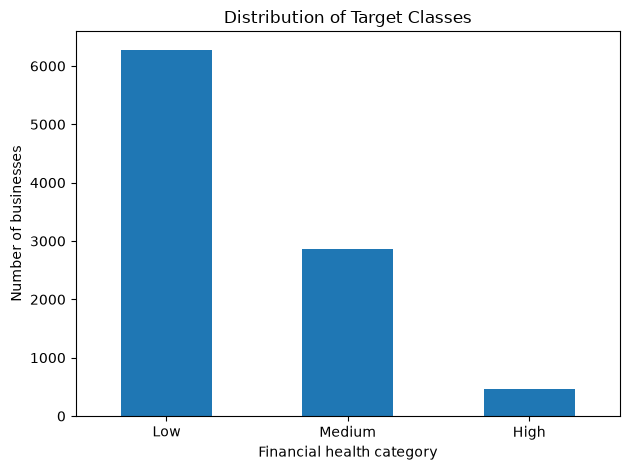

In [7]:

duplicate_count = train_data.duplicated().sum()
print("Number of fully duplicated training rows:", duplicate_count)
if "Target" not in train_data.columns:
    raise KeyError("The training data does not contain a 'Target' column.")
print("\nTarget class counts:")
display(train_data["Target"].value_counts(dropna=False).to_frame("Count"))
print("\nTarget class percentages:")
display(
    (
        train_data["Target"]
        .value_counts(normalize=True, dropna=False) * 100
    ).round(2).to_frame("Percentage")
)
train_data["Target"].value_counts().plot(
    kind="bar",
    xlabel="Financial health category",
    ylabel="Number of businesses",
    title="Distribution of Target Classes",
    rot=0
)

plt.tight_layout()
plt.show()



## 5. Separating the features and target
- Features (`X`) are the information provided to the model as an input.
- Target (`y`) is the answer the model learns to predict. means that the financial health category the model predict

In [29]:

X = train_data.drop(columns=["Target"]).copy()
y = train_data["Target"].copy()
X_test = test_data.copy()
if y.isnull().any():
    raise ValueError(
        "The Target column contains missing labels. "
        "Investigate these rows before training."
    )
train_only = sorted(set(X.columns) - set(X_test.columns))
test_only = sorted(set(X_test.columns) - set(X.columns))
print("Number of training features:", X.shape[1])
print("Number of test features:", X_test.shape[1])
print("Training-only columns:", train_only)
print("Test-only columns:", test_only)
if train_only or test_only:
    raise ValueError(
        "Training and test features do not match. "
        "Investigate the listed columns before continuing."
    )
X_test = X_test[X.columns]
print("\nFeatures and target are ready.")
print("X shape:", X.shape)
print("y shape:", y.shape)
print("X_test shape:", X_test.shape)

Number of training features: 38
Number of test features: 38
Training-only columns: []
Test-only columns: []

Features and target are ready.
X shape: (9618, 38)
y shape: (9618,)
X_test shape: (2405, 38)



## 6. Identifying feature types
Different types of data need different preparation.
- Numeric features can be filled with a statistic such as the median.
- Categorical features can be filled with their most frequent value and encoded into numeric columns.
We will identify the columns by their data types rather than manually typing every column name.

In [30]:

numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()
categorical_features = X.select_dtypes(
    exclude=["number"]
).columns.tolist()
print("Numeric features:")
print(numeric_features)
print("\nCategorical features:")
print(categorical_features)
print("\nNumber of numeric features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))


Numeric features:
['owner_age', 'personal_income', 'business_expenses', 'business_turnover', 'business_age_years', 'business_age_months']

Categorical features:
['ID', 'country', 'attitude_stable_business_environment', 'attitude_worried_shutdown', 'compliance_income_tax', 'perception_insurance_doesnt_cover_losses', 'perception_cannot_afford_insurance', 'motor_vehicle_insurance', 'has_mobile_money', 'current_problem_cash_flow', 'has_cellphone', 'owner_sex', 'offers_credit_to_customers', 'attitude_satisfied_with_achievement', 'has_credit_card', 'keeps_financial_records', 'perception_insurance_companies_dont_insure_businesses_like_yours', 'perception_insurance_important', 'has_insurance', 'covid_essential_service', 'attitude_more_successful_next_year', 'problem_sourcing_money', 'marketing_word_of_mouth', 'has_loan_account', 'has_internet_banking', 'has_debit_card', 'future_risk_theft_stock', 'medical_insurance', 'funeral_insurance', 'motivation_make_more_money', 'uses_friends_family_savin


## 7. Creating training and testing datasets
We will split the available labeled data into:

- Training set: used to fit the model.
- testing set: used to compare models and estimate how well they generalize.
  and use `stratify=y`. Stratification tries to preserve the proportions of the target categories in both sets.

In [31]:

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)
print("Training features:", X_train.shape)
print("testing features:", X_valid.shape)
print("Training labels:", y_train.shape)
print("testing labels:", y_valid.shape)
print("\nTraining target proportions:")
display(y_train.value_counts(normalize=True).round(3).to_frame("Proportion"))
print("\ntesting target proportions:")
display(y_valid.value_counts(normalize=True).round(3).to_frame("Proportion"))


Training features: (7694, 38)
testing features: (1924, 38)
Training labels: (7694,)
testing labels: (1924,)

Training target proportions:


,Proportion
Target,
Low,0.653
Medium,0.298
High,0.049



testing target proportions:


,Proportion
Target,
Low,0.653
Medium,0.298
High,0.049



## 8. Preparing numeric and categorical features

For numeric columns, we will:

   1. Fill missing values with the median.
   2. Scale the values using `StandardScaler`.

For categorical columns, we will:

  1. Fill missing values with the most frequent category.
  2. Apply one-hot encoding to convert categories into numeric columns.

In [32]:

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])



## 9. Training machine learning algorithms
We will compare four classification algorithms:
1. Logistic Regression
2. Decision Tree
3. Random Forest
4. Extra Trees

Each model will receive the same preprocessing pipeline. This makes the comparison fairer and keeps data preparation connected to model training.

In [33]:

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}
pipelines = {}
for model_name, model in models.items():
    pipelines[model_name] = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

print("Models created:", list(pipelines.keys()))


Models created: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'Extra Trees']



## 10. Comparing model performance
For each algorithm, we will:
1. Fit the pipeline using the training split.
2. Predict the validation split.
3. Calculate accuracy.
4. Calculate macro F1-score.
5. Store the results in a table.
Macro F1 calculates the F1-score for each class and then averages the scores equally.
We will use validation macro F1 as our primary model-selection metric.


In [34]:

results = []
for model_name, pipeline in pipelines.items():
    print(f"Training {model_name}...")
    pipeline.fit(X_train, y_train)
    valid_predictions = pipeline.predict(X_valid)
    accuracy = accuracy_score(y_valid, valid_predictions)
    macro_f1 = f1_score(
        y_valid,
        valid_predictions,
        average="macro",
        zero_division=0
    )
    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Macro_F1": macro_f1
    })
results_df = pd.DataFrame(results).sort_values(
    by="Macro_F1",
    ascending=False
).reset_index(drop=True)
display(results_df)


Training Logistic Regression...
Training Decision Tree...
Training Random Forest...
Training Extra Trees...


,Model,Accuracy,Macro_F1
0,Decision Tree,0.840437,0.772062
1,Logistic Regression,0.830561,0.753440
2,Random Forest,0.831081,0.721737
3,Extra Trees,0.837318,0.703546



## 11. Selecting the best model
    We will select the model with the highest validation macro F1-score.
This does not prove that it will achieve the highest score on the competition's hidden labels, but it gives us a consistent basis for choosing among the models we tested.


In [35]:

best_model_name = results_df.loc[0, "Model"]
best_model = pipelines[best_model_name]
print("Best model:", best_model_name)
print(
    "Validation macro F1:",
    round(results_df.loc[0, "Macro_F1"], 4)
)
print(
    "Validation accuracy:",
    round(results_df.loc[0, "Accuracy"], 4)
)


Best model: Decision Tree
Validation macro F1: 0.7721
Validation accuracy: 0.8404



## 12. Checking performance for each class
A single score does not tell us everything about a classifier.
The classification report provides:
- **Precision:** Of the predictions made for a class, how many were correct?
- **Recall:** Of the real examples in a class, how many did the model find?
- **F1-score:** A balance between precision and recall.
- **Support:** How many real examples of that class appear in the validation set.
We will inspect the report to see whether the selected model performs well across Low, Medium, and High.


In [37]:

best_valid_predictions = best_model.predict(X_valid)
print(
    classification_report(
       y_valid,
        best_valid_predictions,
        zero_division=0
    )
)


              precision    recall  f1-score   support

        High       0.68      0.69      0.68        94
         Low       0.89      0.91      0.90      1256
      Medium       0.75      0.72      0.73       574

    accuracy                           0.84      1924
   macro avg       0.77      0.77      0.77      1924
weighted avg       0.84      0.84      0.84      1924




## 13. Visualizing classification mistakes
A confusion matrix compares the actual class with the predicted class.
- Rows represent the actual classes.
- Columns represent the predicted classes.
- The diagonal cells show correct predictions.
- Off-diagonal cells show mistakes.

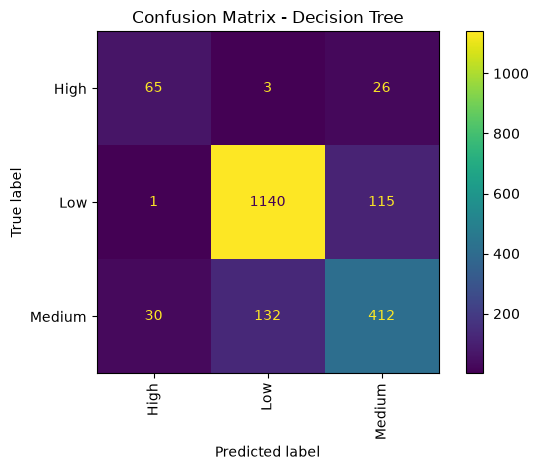

In [38]:

ConfusionMatrixDisplay.from_predictions(
   y_valid,
    best_valid_predictions,
    xticks_rotation="vertical",
    values_format="d"
)
plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()


## 14. Reviewing the model comparison
Before making predictions for the test data, we have:
- Compared multiple algorithms on the same validation split.
- Selected the model with the highest validation macro F1.
- Examined the classification report.
- Examined the confusion matrix.

The next step is to train the selected pipeline again using all available labeled training data. This allows the final model to learn from the validation rows too.


In [39]:

final_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", models[best_model_name])
])
final_model.fit(X, y)
print("Final model trained on all labeled training data.")


Final model trained on all labeled training data.



## 15. Predicting financial health for the test dataset

 We will now use the final trained model to predict the target category for each row in the test dataset.

The model will apply the same preprocessing steps it learned during training. We should not separately fit a new encoder or imputer on the test data.

These predictions are not known ground-truth labels. They are the model's estimates.


In [43]:

test_predictions = final_model.predict(X_test)
print("Number of test rows:", len(X_test))
print("Number of predictions:", len(test_predictions))

# Display the first few predictions.
print("\nFirst 10 predictions:")
print(test_predictions[:10])

# Count how many times the model predicts each category.
print("\nPredicted class counts:")
display(
    pd.Series(test_predictions, name="Predicted_Target")
    .value_counts()
    .to_frame("Count")
)


Number of test rows: 2405
Number of predictions: 2405

First 10 predictions:
['Low' 'Medium' 'Low' 'Medium' 'Low' 'Medium' 'Low' 'Low' 'Medium' 'Low']

Predicted class counts:


,Count
Predicted_Target,
Low,1565
Medium,699
High,141


## 16. Creating the submission file
now let as save the final prediction result based on the test data 

In [59]:
out_path=Path("../data/submition.csv")
prediction_result=pd.DataFrame({"Target":test_predictions})
prediction_result.to_csv(out_path,index=False)


## Now save the traind model

In [61]:
model_path = Path("../model/sme_financial_health_model.joblib")
joblib.dump(final_model,model_path)

['..\\model\\sme_financial_health_model.joblib']